# A Series to Understanding Marketing Performance — Pt. 8: Personalized Offer Scoring (Uplift)

This notebook is a Jupyter conversion of the companion blog post (`A Series to Understanding Marketing Performance Pt 8`). It has been broken out into one section per logical step, each with a short explanation ahead of the code that performs it, and extra inline comments throughout.

**Pipeline overview:**

1. Generate a synthetic sample dataset standing in for the marketing database (no live DB connection needed)
2. Simulate historical offer/campaign data **with a randomized control group** — customers who received no offer at all, which is what makes measuring the offer's true effect possible
3. Engineer features describing each customer and campaign interaction
4. Train a **two-model uplift system**: one response model + one revenue model on the treatment group, the same pair on the control group — the gap between a treatment prediction and a control prediction, for the same customer, is the estimated uplift
5. Wrap all four models in an `OfferUpliftScoringSystem` that scores any customer × offer × channel combination
6. Score a specific campaign and run a full offer/channel optimization sweep, ranked by **incremental** value
7. Visualize the results, including the treated-vs-control gap that the whole exercise is trying to measure


## 1. Setup & Imports

Load the libraries used across the whole notebook: `pandas`/`numpy` for data wrangling (including generating the sample dataset below), `matplotlib`/`seaborn` for the charts at the end, and `datetime` for the recency calculations used later in feature engineering.


In [1]:
# Core data manipulation
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Date handling (used for recency calculations later in this notebook)
from datetime import datetime, timedelta

# Suppress noisy library warnings so printed output stays readable
import warnings
warnings.filterwarnings('ignore')


## 2. Generate Sample Data

This notebook only needs two tables — `customers` and `orders` — so rather than connecting to a live database, we generates a synthetic stand-in for both tables:

- **`customers`**: `customer_id`, `registration_date`, `first_purchase_date`, `acquisition_channel` (`organic_search`, `email_marketing`, `google_ads`, `facebook_ads`, `referral`), `customer_segment` (`high_value`/`medium_value`/`low_value`, split roughly 37/37/25%, matching the real table)
- **`orders`**: `order_id`, `customer_id`, `order_date`, `order_value`, `product_cost`, `shipping_cost` — each customer gets 1-5 orders placed after their first purchase, with `order_value` centered around $253 (the real table's average) and `product_cost` set to roughly half of `order_value`

We add `marketing_spend` and `attribution_touchpoints` for continuity with the original four-table schema I created, but nothing downstream in this notebook actually reads them.


In [2]:
# Generate a synthetic sample dataset standing in for the marketing_guide
# Postgres tables, so this notebook can run standalone with no database.
np.random.seed(7)

n_customers = 50

# Segment and acquisition-channel mix roughly matches the real customers table
customer_segments = np.random.choice(
    ['high_value', 'medium_value', 'low_value'],
    size=n_customers, p=[0.375, 0.375, 0.25]
)
acquisition_channels = np.random.choice(
    ['organic_search', 'email_marketing', 'google_ads', 'facebook_ads', 'referral'],
    size=n_customers, p=[0.21, 0.17, 0.23, 0.23, 0.16]
)

# Registration dates spread across a ~8 month window, with each customer's
# first purchase landing some days to a few weeks after they register
registration_dates = pd.to_datetime('2023-01-01') + pd.to_timedelta(
    np.random.randint(0, 240, size=n_customers), unit='D'
)
first_purchase_dates = registration_dates + pd.to_timedelta(
    np.random.randint(1, 30, size=n_customers), unit='D'
)

customers = pd.DataFrame({
    'customer_id': range(1, n_customers + 1),
    'registration_date': registration_dates,
    'first_purchase_date': first_purchase_dates,
    'acquisition_channel': acquisition_channels,
    'customer_segment': customer_segments
})

# Orders: each customer places a handful of orders sometime after their
# first purchase. product_cost/shipping_cost are kept around the real
# table's averages (~50% of order_value, and ~$12, respectively).
order_rows = []
order_id = 1
for _, cust in customers.iterrows():
    n_orders = np.random.randint(1, 6)
    for _ in range(n_orders):
        order_date = cust['first_purchase_date'] + pd.Timedelta(days=int(np.random.randint(0, 365)))
        order_value = max(45, np.random.normal(253, 90))
        order_rows.append({
            'order_id': order_id,
            'customer_id': cust['customer_id'],
            'order_date': order_date,
            'order_value': round(order_value, 2),
            'product_cost': round(order_value * 0.5, 2),
            'shipping_cost': round(np.random.uniform(5, 20), 2)
        })
        order_id += 1

orders = pd.DataFrame(order_rows)

# Not used by anything downstream in this notebook - generated only to keep
# the same four tables as the real schema.
marketing_spend = pd.DataFrame({
    'date': pd.date_range('2023-01-01', periods=90, freq='D'),
    'channel': np.random.choice(
        ['organic_search', 'email_marketing', 'google_ads', 'facebook_ads', 'referral'], size=90
    ),
    'spend': np.random.uniform(100, 1000, size=90).round(2),
    'impressions': np.random.randint(1000, 20000, size=90),
    'clicks': np.random.randint(50, 800, size=90)
})

attribution_touchpoints = pd.DataFrame({
    'touchpoint_id': range(1, n_customers + 1),
    'customer_id': customers['customer_id'],
    'channel': customers['acquisition_channel'],
    'touchpoint_date': customers['registration_date'],
    'conversion_value': np.random.uniform(0, 300, size=n_customers).round(2),
    'position_in_journey': 1
})

print(f"Generated {len(customers)} sample customers and {len(orders)} sample orders")
print(customers['customer_segment'].value_counts())


Generated 50 sample customers and 141 sample orders
customer_segment
medium_value    22
high_value      17
low_value       11
Name: count, dtype: int64


## 8. Personalized Offer Scoring

Personalized offer scoring predicts which offers or promotions will be most effective for individual customers, enabling targeted marketing campaigns.

### Understanding Offer Scoring

Offer scoring typically considers:

- **Customer preferences**: Based on past behavior
- **Propensity to respond**: Likelihood of engagement
- **Revenue potential**: Expected value from the offer
- **Channel preferences**: Preferred communication methods

### Propensity vs. Uplift

A plain propensity model answers "how likely is this customer to respond to this offer?" That mixes together customers who convert *because of* the offer with customers who would have bought anyway — targeting the latter just gives away margin for free.

An **uplift model** asks a sharper question instead: "how much does *giving this customer the offer* change their behavior, compared to giving them nothing?" Estimating that requires seeing both outcomes — customers who received the offer (the **treatment** group) and a comparable group who received nothing at all (the **control** group) — so the model can learn the gap between them.

Below, the simulation is extended to include a randomized control group, and the model is rebuilt as a simple **two-model uplift approach**: one model trained on the treatment group, one trained on the control group, and the difference between their predictions for the same customer is the estimated uplift.


## 3. Modeling Imports

This stage needs scikit-learn. With the uplift approach, the same two model *types* are used as before, just trained twice each — once per arm:

- `RandomForestClassifier` — predicts response probability, trained separately on the treatment rows and the control rows
- `RandomForestRegressor` — predicts revenue conditional on responding, also trained separately per arm

`train_test_split` carves out a holdout set; `LabelEncoder` turns the string categories (`offer_type`, `channel`, `customer_segment`, `acquisition_channel`) into integers; `roc_auc_score` scores each arm's classifier; `itertools` enumerates every (offer_type, channel) pair during optimization.


In [3]:
import itertools

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

# Evaluates each arm's response-probability classifier
from sklearn.metrics import roc_auc_score

# train_test_split carves out the holdout set used to evaluate the response models below.
# cross_val_score is imported but not used in this notebook — left available if you want
# to add k-fold cross-validation on top of the single train/test split.
from sklearn.model_selection import cross_val_score, train_test_split

# Encodes string categories (offer_type, channel, segment, acquisition_channel) into integers
from sklearn.preprocessing import LabelEncoder


## 4. Simulate Historical Offer/Campaign Data — With a Control Group

There's no real "offer history" table in this schema, so `create_comprehensive_offer_data` **synthesizes one** — and this version adds the piece a propensity model can't use: a randomized **control group**.

For every campaign, an eligible audience is selected as before, but now each eligible customer is independently coin-flipped into:

- **Control** (`treatment = 0`): receives *nothing*. Still gets an **organic baseline probability that varies by segment** — `high_value` customers start at 12%, `medium_value` at 7%, `low_value` at 4% — representing that more loyal/frequent buyers convert at a higher rate even with no nudge at all. This is deliberate: it creates the classic uplift-modeling "sure thing" case, where a segment can show a high *raw* response rate that has nothing to do with any offer.
- **Treatment** (`treatment = 1`): gets that same segment baseline, **plus** a small universal "something was offered" bump, **plus** a larger **segment-offer affinity bonus** only when this specific offer type matches what the segment responds to best (e.g. `high_value` + `discount_20`/`cashback`), **plus** a channel bonus — and, if they respond, a revenue boost from the offer's own mechanics (`bogo`/`discount_20` multipliers).

Because the *only* systematic difference between the two groups is whether they got the offer — the segment-based organic baseline is identical in both arms — the gap in outcomes between them is the offer's true causal effect, isolated from each segment's "would have bought anyway" baseline. A segment with a high control-group response rate but a *small* gap versus its treatment group is exactly the "sure thing" a propensity model would over-target and an uplift model correctly avoids.


In [4]:
# Create comprehensive offer simulation, now with a randomized control group
def create_comprehensive_offer_data(customers_df, n_campaigns=100):
    np.random.seed(42)

    offer_types = ['discount_10', 'discount_20', 'free_shipping', 'bogo', 'cashback']
    channels = ['email', 'sms', 'push_notification', 'direct_mail']

    offer_history = []

    for campaign_id in range(1, n_campaigns + 1):
        # Random campaign parameters
        offer_type = np.random.choice(offer_types)
        channel = np.random.choice(channels)

        # Select the eligible audience for this campaign (varying campaign sizes)
        campaign_size = np.random.uniform(0.2, 0.8)
        selected_customers = customers_df.sample(frac=campaign_size)

        for _, customer in selected_customers.iterrows():
            # Randomly hold out half of the eligible audience as a control
            # group that receives NO offer. This is what makes uplift
            # modeling possible: without a control group, there's no way to
            # know what a customer would have done anyway.
            treatment = np.random.binomial(1, 0.5)

            # Baseline (organic) probability of responding with NO offer at
            # all. This now varies by segment, on purpose: high-value
            # customers are more loyal/frequent buyers even with no nudge -
            # the classic uplift-modeling "sure thing" case, where a high
            # raw response rate doesn't mean the offer itself did much.
            if customer['customer_segment'] == 'high_value':
                base_prob = 0.12
            elif customer['customer_segment'] == 'medium_value':
                base_prob = 0.07
            else:  # low_value
                base_prob = 0.04

            if treatment:
                # Simply being offered something (regardless of fit) gives a
                # small universal bump on top of the organic baseline above.
                base_prob += 0.05

                # Segment-offer affinity adds MORE on top of that, but only
                # when this specific offer type matches what the segment
                # responds to best - this is the part of the probability
                # that represents a well-targeted offer's true added effect.
                if customer['customer_segment'] == 'high_value':
                    if offer_type in ['discount_20', 'cashback']:
                        base_prob += 0.2
                elif customer['customer_segment'] == 'medium_value':
                    if offer_type in ['discount_10', 'free_shipping']:
                        base_prob += 0.15
                else:  # low_value
                    if offer_type in ['bogo', 'free_shipping']:
                        base_prob += 0.1

                # Channel influence
                if channel == 'email':
                    base_prob += 0.05
                elif channel == 'sms':
                    base_prob += 0.03

            # Add some randomness
            response_prob = min(base_prob + np.random.normal(0, 0.05), 0.8)
            response_prob = max(response_prob, 0.01)

            responded = np.random.binomial(1, response_prob)

            # Revenue if responded
            if responded:
                base_revenue = 100
                if customer['customer_segment'] == 'high_value':
                    base_revenue = 200
                elif customer['customer_segment'] == 'medium_value':
                    base_revenue = 150

                # Offer type influence on revenue only applies to customers
                # who actually got the offer - a control customer who buys
                # anyway has no offer mechanics boosting their basket size.
                if treatment:
                    if offer_type == 'discount_20':
                        base_revenue *= 1.3
                    elif offer_type == 'bogo':
                        base_revenue *= 1.5

                revenue = max(0, np.random.normal(base_revenue, base_revenue * 0.3))
            else:
                revenue = 0

            offer_history.append({
                'campaign_id': campaign_id,
                'customer_id': customer['customer_id'],
                'acquisition_channel': customer['acquisition_channel'],
                'customer_segment': customer['customer_segment'],
                'offer_type': offer_type,
                'channel': channel,
                'treatment': treatment,
                'responded': responded,
                'revenue': revenue
            })

    return pd.DataFrame(offer_history)


## 5. Generate & Inspect the Simulated Dataset

Run the simulator and print a quick sanity-check summary: total campaigns, total customer-offer interactions, the treated/control split, and — most importantly — the raw response-rate gap between the two groups. That gap is the ground-truth signal the uplift model is trying to recover.


In [5]:
offer_data = create_comprehensive_offer_data(customers)
print("Offer Campaign Simulation Overview:")
print(f"Total campaigns: {offer_data['campaign_id'].nunique()}")
print(f"Total customer-offer interactions: {len(offer_data)}")
print(f"Treated (received an offer): {offer_data['treatment'].mean():.1%} of interactions")
print(f"Response rate - treatment group: {offer_data.loc[offer_data['treatment'] == 1, 'responded'].mean():.2%}")
print(f"Response rate - control group:   {offer_data.loc[offer_data['treatment'] == 0, 'responded'].mean():.2%}")


Offer Campaign Simulation Overview:
Total campaigns: 100
Total customer-offer interactions: 2548
Treated (received an offer): 49.9% of interactions
Response rate - treatment group: 21.70%
Response rate - control group:   6.82%


## 6. Aggregate Offer Performance by Type & Segment

Look at the raw simulated performance for every (`offer_type`, `customer_segment`) combination — campaigns, customers targeted, responses, and revenue. This is restricted to the **treatment group only**, since control customers were never actually given a specific `offer_type` to evaluate.


In [6]:
# Analyze offer performance (treatment group only - control customers
# weren't actually given a specific offer_type to evaluate)
offer_performance = offer_data[offer_data['treatment'] == 1].groupby(['offer_type', 'customer_segment']).agg({
    'campaign_id': 'nunique',
    'customer_id': 'count',
    'responded': ['sum', 'mean'],
    'revenue': ['sum', 'mean']
}).round(3)

# Flatten the resulting MultiIndex columns into readable names
offer_performance.columns = ['campaigns', 'customers_targeted', 'total_responses',
                           'response_rate', 'total_revenue', 'avg_revenue']

print("\nOffer Performance by Type and Segment (treatment group):")
print(offer_performance)



Offer Performance by Type and Segment (treatment group):
                                campaigns  customers_targeted  \
offer_type    customer_segment                                  
bogo          high_value               21                 100   
              low_value                20                  60   
              medium_value             21                 131   
cashback      high_value               16                  79   
              low_value                16                  46   
              medium_value             16                  94   
discount_10   high_value               23                  84   
              low_value                22                  56   
              medium_value             23                 124   
discount_20   high_value               23                 109   
              low_value                20                  65   
              medium_value             23                 123   
free_shipping high_value        

## 7. Feature Engineering for the Scoring Model

`create_offer_features` turns the raw `offer_data` + `customers` + `orders` tables into a single model-ready DataFrame:

1. **Customer purchase history** — for every customer, aggregate their orders into `avg_order_value`, `order_value_std`, `total_orders`, `total_spent`, and `first_order`/`last_order` dates.
2. **Recency** — `days_since_last_order`, measured against each customer's own last-order date plus a fixed 35-day offset (a simple stand-in for "today").
3. **Merge** that history onto every offer interaction, then re-merge clean `acquisition_channel`/`customer_segment` columns straight from `customers_df` (dropping the first copies) so there's no ambiguity about which version is authoritative.
4. **Label-encode** every categorical column (`offer_type`, `channel`, `customer_segment`, `acquisition_channel`) into integers the models can consume.
5. **Interaction features** — `segment_offer_interaction` and `channel_offer_interaction` combine two encoded categories into one number (`encoded_a * 10 + encoded_b`), letting a tree-based model split on segment×offer or channel×offer combinations directly.

The `treatment` column (0 = control, 1 = received the offer) passes straight through untouched — it's the label the uplift models split on in the next section, not something that needs encoding.

It returns the enhanced DataFrame along with the four fitted `LabelEncoder`s, since the same encoders are needed later to encode new offer/channel values when scoring.


In [7]:
# Enhanced feature engineering for offer scoring
def create_offer_features(offer_df, customers_df, orders_df):

  # For troubleshooting.
  #offer_df = offer_data
  #customers_df = customers
  #orders_df = orders

    # Customer historical features
  customer_history = orders_df.groupby('customer_id').agg({
      'order_value': ['mean', 'std', 'count', 'sum'],
      'order_date': ['min', 'max']
  }).round(2)

  customer_history.columns = ['avg_order_value', 'order_value_std', 'total_orders',
                              'total_spent', 'first_order', 'last_order']
  customer_history = customer_history.reset_index()

  # Calculate recency: days between each customer's last order and a fixed
  # 35-day-later reference point (a simple stand-in for "today")
  customer_history['last_order'] = pd.to_datetime(customer_history['last_order'])
  analysis_date = pd.to_datetime(customer_history['last_order'] + pd.Timedelta(days=35))
  customer_history['days_since_last_order'] = (analysis_date - customer_history['last_order']).dt.days

  # Merge all features
  enhanced_offer_data = offer_df.merge(customer_history, on='customer_id', how='left')
  # Added this one to remove duplicate columns 'acquisition_channel', 'customer_segment'.
  enhanced_offer_data = enhanced_offer_data.drop(columns=['acquisition_channel', 'customer_segment'])
  enhanced_offer_data = enhanced_offer_data.merge(customers_df[['customer_id', 'acquisition_channel', 'customer_segment']], on='customer_id', how='left')

  # Encode categorical variables
  le_offer = LabelEncoder()
  le_channel = LabelEncoder()
  le_segment = LabelEncoder()
  le_acq_channel = LabelEncoder()

  enhanced_offer_data['offer_type_encoded'] = le_offer.fit_transform(enhanced_offer_data['offer_type'])
  enhanced_offer_data['channel_encoded'] = le_channel.fit_transform(enhanced_offer_data['channel'])
  enhanced_offer_data['segment_encoded'] = le_segment.fit_transform(enhanced_offer_data['customer_segment'])
  enhanced_offer_data['acq_channel_encoded'] = le_acq_channel.fit_transform(enhanced_offer_data['acquisition_channel'])

  # Create interaction features: combine two encoded categories into a single
  # number so a tree model can split on segment x offer (or channel x offer)
  # combinations directly, instead of having to discover the interaction itself.
  enhanced_offer_data['segment_offer_interaction'] = (enhanced_offer_data['segment_encoded'] * 10 +
                                                      enhanced_offer_data['offer_type_encoded'])
  enhanced_offer_data['channel_offer_interaction'] = (enhanced_offer_data['channel_encoded'] * 10 +
                                                      enhanced_offer_data['offer_type_encoded'])

  # 'treatment' (0 = control, 1 = received the offer) passes straight through
  # from offer_df - it's the label the uplift models below split on.
  return enhanced_offer_data, le_offer, le_channel, le_segment, le_acq_channel


## 8. Build the Enhanced Feature Set

Apply `create_offer_features` to the simulated offer data. Keep the four fitted encoders (`offer_le`, `channel_le`, `segment_le`, `acq_channel_le`) around — the `OfferUpliftScoringSystem` below reuses them so that any new offer/channel/segment value is encoded exactly the same way it was during training.


In [8]:
enhanced_offer_data, offer_le, channel_le, segment_le, acq_channel_le = create_offer_features(offer_data, customers, orders)


## 9. Train the Uplift Models (Two-Model / T-Learner Approach)

`build_uplift_models` trains the uplift system using the simplest well-known technique — the **two-model** approach (also called a **T-learner**): train a completely separate pair of models for each arm, rather than one model that somehow knows about both.

1. Assemble the feature matrix `X` and three companion columns: `treatment` (the arm label), `responded`, and `revenue`.
2. **Single 70/30 train/test split**, shared across everything, via `train_test_split`.
3. Split the *training* rows into `train_treated` and `train_control` masks.
4. **Two response models** — a `RandomForestClassifier` fit on the treatment rows only, and another fit on the control rows only.
5. **Two revenue models** — a `RandomForestRegressor` per arm, each trained only on that arm's responders (non-responders trivially generated $0 revenue, so including them would just dilute the regression).
6. **Evaluate separately per arm**, printing each arm's held-out AUC.
7. **Sanity-check the uplift itself** — average the *difference* between the two response models' predictions across the whole test set, and compare that to the actual observed response-rate gap between treated and control test rows. If the model is working, those two numbers should be close.

Returns all four fitted models plus the feature column list.


In [9]:
# Build offer scoring models - the "two-model" (a.k.a. T-learner) uplift
# approach: train one response model and one revenue model on the treatment
# group, and the same pair on the control group. The gap between a
# treatment-model prediction and a control-model prediction, for the SAME
# customer, is the estimated uplift - the effect of the offer itself.
def build_uplift_models(df):
    # Features for modeling (note: 'treatment' is the split key below, not a
    # feature - each model only ever sees customers from its own arm)
    feature_columns = [
        'offer_type_encoded', 'channel_encoded', 'segment_encoded', 'acq_channel_encoded',
        'avg_order_value', 'order_value_std', 'total_orders', 'total_spent',
        'days_since_last_order', 'segment_offer_interaction', 'channel_offer_interaction'
    ]

    # Handle missing values
    modeling_data = df[feature_columns + ['treatment', 'responded', 'revenue']].fillna(0)

    X = modeling_data[feature_columns]
    treatment = modeling_data['treatment']
    y_response = modeling_data['responded']
    y_revenue = modeling_data['revenue']

    # One shared train/test split, then separate the training set into its
    # treatment and control arms below
    X_train, X_test, t_train, t_test, y_resp_train, y_resp_test, y_rev_train, y_rev_test = train_test_split(
        X, treatment, y_response, y_revenue, test_size=0.3, random_state=42
    )

    train_treated = t_train == 1
    train_control = t_train == 0

    # Response probability models - one per arm
    response_model_treatment = RandomForestClassifier(n_estimators=100, random_state=42)
    response_model_treatment.fit(X_train[train_treated], y_resp_train[train_treated])

    response_model_control = RandomForestClassifier(n_estimators=100, random_state=42)
    response_model_control.fit(X_train[train_control], y_resp_train[train_control])

    # Revenue prediction models - one per arm, each trained only on that
    # arm's responders (non-responders trivially generated $0)
    revenue_model_treatment = RandomForestRegressor(n_estimators=100, random_state=42)
    treated_responders = train_treated & (y_rev_train > 0)
    revenue_model_treatment.fit(X_train[treated_responders], y_rev_train[treated_responders])

    revenue_model_control = RandomForestRegressor(n_estimators=100, random_state=42)
    control_responders = train_control & (y_rev_train > 0)
    revenue_model_control.fit(X_train[control_responders], y_rev_train[control_responders])

    # Evaluate each arm's response model on its own held-out rows
    test_treated = t_test == 1
    test_control = t_test == 0

    treatment_auc = roc_auc_score(y_resp_test[test_treated], response_model_treatment.predict_proba(X_test[test_treated])[:, 1])
    control_auc = roc_auc_score(y_resp_test[test_control], response_model_control.predict_proba(X_test[test_control])[:, 1])

    print(f"Treatment-arm Response Model AUC: {treatment_auc:.3f}")
    print(f"Control-arm Response Model AUC:   {control_auc:.3f}")

    # Sanity check: average the two models' predicted uplift across the
    # WHOLE test set, and compare it to the actual observed response-rate
    # gap between the treated and control rows in that same test set. If the
    # model is working, these two numbers should land in the same ballpark.
    predicted_uplift = (response_model_treatment.predict_proba(X_test)[:, 1] -
                         response_model_control.predict_proba(X_test)[:, 1])
    actual_gap = y_resp_test[test_treated].mean() - y_resp_test[test_control].mean()

    print(f"\nAverage predicted response uplift (test set): {predicted_uplift.mean():.3f}")
    print(f"Actual observed response-rate gap, treated minus control (test set): {actual_gap:.3f}")

    return (response_model_treatment, response_model_control,
            revenue_model_treatment, revenue_model_control, feature_columns)


## 10. Fit the Models

Run the training function against `enhanced_offer_data`. This prints each arm's AUC and the predicted-vs-actual uplift sanity check defined above.


In [10]:
(response_model_treatment, response_model_control,
 revenue_model_treatment, revenue_model_control, feature_cols) = build_uplift_models(enhanced_offer_data)


Treatment-arm Response Model AUC: 0.606
Control-arm Response Model AUC:   0.508

Average predicted response uplift (test set): 0.139
Actual observed response-rate gap, treated minus control (test set): 0.119


## 11. The Offer Uplift Scoring System

`OfferUpliftScoringSystem` packages all four trained models (plus the four label encoders) into a reusable object with three methods:

- **`_prepare_customer_features`** — rebuilds the same order-history/recency features used in training, for an arbitrary set of customers, and label-encodes `customer_segment`/`acquisition_channel` using the *already-fitted* encoders.
- **`score_offers_for_customers`** — for one specific `offer_type`/`channel`, runs every customer through **both** arms' models — "if offered" and "if not offered" — producing `response_prob_if_offered`, `response_prob_if_not_offered`, and the same pair for revenue. The differences between those (`response_uplift`, `incremental_value`) are the actual uplift estimates, rescaled into a 0–100 `uplift_score` for easy ranking.
- **`optimize_campaign`** — sweeps every combination of the given `offer_types` × `channels`, scores customers for each, and — critically — **keeps only customers with positive predicted uplift** before computing ROI. A customer with negative or zero uplift would convert anyway (or is put off by the offer), so sending it to them just gives away margin for nothing.


In [11]:
# Offer uplift scoring system: wraps the four arm-specific models and uses
# the gap between their predictions - for the SAME customer - as the
# estimated effect of the offer.
class OfferUpliftScoringSystem:
    def __init__(self, response_model_treatment, response_model_control,
                 revenue_model_treatment, revenue_model_control, feature_columns, encoders):
        self.response_model_treatment = response_model_treatment
        self.response_model_control = response_model_control
        self.revenue_model_treatment = revenue_model_treatment
        self.revenue_model_control = revenue_model_control
        self.feature_columns = feature_columns
        self.offer_le, self.channel_le, self.segment_le, self.acq_channel_le = encoders

    def score_offers_for_customers(self, customers_df, orders_df, offer_type, channel):
        # Prepare customer features
        customer_features = self._prepare_customer_features(customers_df, orders_df)

        # Encode offer and channel using the encoders fitted during training
        try:
            offer_encoded = self.offer_le.transform([offer_type])[0]
            channel_encoded = self.channel_le.transform([channel])[0]
        except ValueError:
            print(f"Warning: Unknown offer_type '{offer_type}' or channel '{channel}'")
            return pd.DataFrame()

        # Create feature matrix - every customer is scored through BOTH the
        # treatment and control models, as if they received this offer AND
        # as if they received nothing, so the two outcomes can be compared.
        scoring_data = customer_features.copy()
        scoring_data['offer_type_encoded'] = offer_encoded
        scoring_data['channel_encoded'] = channel_encoded
        scoring_data['segment_offer_interaction'] = (scoring_data['segment_encoded'] * 10 + offer_encoded)
        scoring_data['channel_offer_interaction'] = (channel_encoded * 10 + offer_encoded)

        X = scoring_data[self.feature_columns].fillna(0)

        # Predict response probability under each scenario
        response_prob_if_offered = self.response_model_treatment.predict_proba(X)[:, 1]
        response_prob_if_not_offered = self.response_model_control.predict_proba(X)[:, 1]

        # Predict revenue under each scenario
        revenue_if_offered = np.maximum(self.revenue_model_treatment.predict(X), 0)
        revenue_if_not_offered = np.maximum(self.revenue_model_control.predict(X), 0)

        # Expected value under each scenario, then the INCREMENTAL value the
        # offer adds on top of what would have happened anyway
        expected_value_if_offered = response_prob_if_offered * revenue_if_offered
        expected_value_if_not_offered = response_prob_if_not_offered * revenue_if_not_offered
        incremental_value = expected_value_if_offered - expected_value_if_not_offered

        # Create results dataframe
        results = customer_features[['customer_id', 'customer_segment']].copy()
        results['offer_type'] = offer_type
        results['channel'] = channel
        results['response_prob_if_offered'] = response_prob_if_offered
        results['response_prob_if_not_offered'] = response_prob_if_not_offered
        results['response_uplift'] = response_prob_if_offered - response_prob_if_not_offered
        results['incremental_value'] = incremental_value
        # Rescale incremental value to a 0-100 score for easy ranking/comparison
        results['uplift_score'] = (incremental_value / incremental_value.max() * 100) if incremental_value.max() > 0 else 0

        return results.sort_values('uplift_score', ascending=False)

    def _prepare_customer_features(self, customers_df, orders_df):
        # Calculate customer historical metrics
        customer_history = orders_df.groupby('customer_id').agg({
            'order_value': ['mean', 'std', 'count', 'sum'],
            'order_date': 'max'
        }).round(2)

        customer_history.columns = ['avg_order_value', 'order_value_std', 'total_orders',
                                   'total_spent', 'last_order']
        customer_history = customer_history.reset_index()

        # Calculate recency against a fixed reference date
        customer_history['last_order'] = pd.to_datetime(customer_history['last_order'])
        analysis_date = pd.to_datetime('2023-12-31')
        customer_history['days_since_last_order'] = (analysis_date - customer_history['last_order']).dt.days

        # Merge with customer data
        customer_features = customers_df.merge(customer_history, on='customer_id', how='left')
        customer_features = customer_features.fillna(0)

        # Encode categorical variables using the already-fitted encoders
        # (never re-fit here, so new data is encoded consistently with training)
        customer_features['segment_encoded'] = self.segment_le.transform(customer_features['customer_segment'])
        customer_features['acq_channel_encoded'] = self.acq_channel_le.transform(customer_features['acquisition_channel'])

        return customer_features

    def optimize_campaign(self, customers_df, orders_df, offer_types, channels, budget_per_customer=5, max_customers=100):
        """Find the best offer-channel-customer combinations within budget, ranked by incremental value"""
        optimization_results = []

        for offer_type, channel in itertools.product(offer_types, channels):
            scores = self.score_offers_for_customers(customers_df, orders_df, offer_type, channel)
            if len(scores) > 0:
                # Only worth targeting customers with POSITIVE uplift - a
                # negative-uplift customer would convert anyway (or is put
                # off by this offer), so sending it just gives away margin
                # for free.
                positive_uplift = scores[scores['incremental_value'] > 0]
                top_scores = positive_uplift.head(max_customers)
                if len(top_scores) == 0:
                    continue
                optimization_results.append({
                    'offer_type': offer_type,
                    'channel': channel,
                    'total_incremental_value': top_scores['incremental_value'].sum(),
                    'avg_response_uplift': top_scores['response_uplift'].mean(),
                    'customers_targeted': len(top_scores),
                    'cost': len(top_scores) * budget_per_customer,
                    'roi': top_scores['incremental_value'].sum() / (len(top_scores) * budget_per_customer),
                    'top_customers': top_scores['customer_id'].tolist()[:10]  # Store top 10 customer IDs
                })

        optimization_df = pd.DataFrame(optimization_results).sort_values('roi', ascending=False)
        return optimization_df


## 12. Initialize the Scoring System

Wrap the four trained models, feature list, and the four fitted encoders into a single `OfferUpliftScoringSystem` instance that the rest of the notebook will call.


In [12]:
# Initialize scoring system
offer_scoring_system = OfferUpliftScoringSystem(
    response_model_treatment, response_model_control,
    revenue_model_treatment, revenue_model_control, feature_cols,
    (offer_le, channel_le, segment_le, acq_channel_le)
)


## 13. Score a Specific Campaign by Incremental Uplift

Rank every customer for one concrete campaign — a 20%-discount offer sent by email — by `uplift_score`, and show the 10 customers the offer is predicted to move the most. These are customers predicted to respond *because of* the offer, not customers who were simply likely to respond regardless.


In [13]:
# Score customers for specific campaign
campaign_scores = offer_scoring_system.score_offers_for_customers(customers, orders, 'discount_20', 'email')
print("Top 10 Customers by Incremental Uplift for 20% Discount Email Campaign:")
print(campaign_scores.head(10)[['customer_id', 'customer_segment', 'response_uplift', 'incremental_value', 'uplift_score']])


Top 10 Customers by Incremental Uplift for 20% Discount Email Campaign:
    customer_id customer_segment  response_uplift  incremental_value  \
41           42       high_value         0.853333         209.036102   
19           20       high_value         0.841333         193.567120   
7             8       high_value         0.630929         159.541344   
43           44       high_value         0.442500         145.360563   
34           35       high_value         0.647639         133.143372   
48           49       high_value         0.725048         127.509589   
37           38       high_value         0.588167         122.574109   
14           15       high_value         0.537000         119.177004   
32           33       high_value         0.884333         114.538090   
0             1       high_value         0.464429         114.513295   

    uplift_score  
41    100.000000  
19     92.599852  
7      76.322388  
43     69.538497  
34     63.693960  
48     60.998836  
37

## 14. Optimize Across Offer Types & Channels, Ranked by Incremental ROI

Sweep every combination of 4 offer types × 2 channels (8 combinations total) through `optimize_campaign`, and rank them by ROI computed on **incremental** value — this answers "which offer/channel strategy actually creates new revenue?", not just "who was likely to buy regardless?"


In [14]:
# Campaign optimization
offer_types = ['discount_10', 'discount_20', 'free_shipping', 'bogo']
channels = ['email', 'sms']

optimization_results = offer_scoring_system.optimize_campaign(customers, orders, offer_types, channels)
print("\nCampaign Optimization Results (Top 5 by ROI):")
print(optimization_results.head()[['offer_type', 'channel', 'total_incremental_value', 'avg_response_uplift', 'roi']])



Campaign Optimization Results (Top 5 by ROI):
      offer_type channel  total_incremental_value  avg_response_uplift  \
5  free_shipping     sms              2289.731645             0.349157   
2    discount_20   email              2457.498592             0.287864   
6           bogo   email              1674.066091             0.176225   
7           bogo     sms              2053.909359             0.180873   
3    discount_20     sms              1836.007311             0.190955   

         roi  
5  11.169423  
2  10.684776  
6   9.049006  
7   8.930041  
3   8.742892  


## 15. Visualize the Results

A 2×2 dashboard tying the whole notebook together:

- **Top-left** — response rate by offer type, **treated vs. control side by side**. The gap between the two bars for each offer type *is* that offer's measured uplift — this is the chart a propensity-only model could never produce, since it never had a control group to compare against.
- **Top-right** — average revenue by customer segment, also treated vs. control.
- **Bottom-left** — ROI from the optimization sweep, grouped by offer type with channel as a separate bar within each group (so email and SMS for the same offer type sit side by side instead of sharing an ambiguous, repeated x-axis label).
- **Bottom-right** — distribution of predicted incremental value across customers for the single campaign scored above.


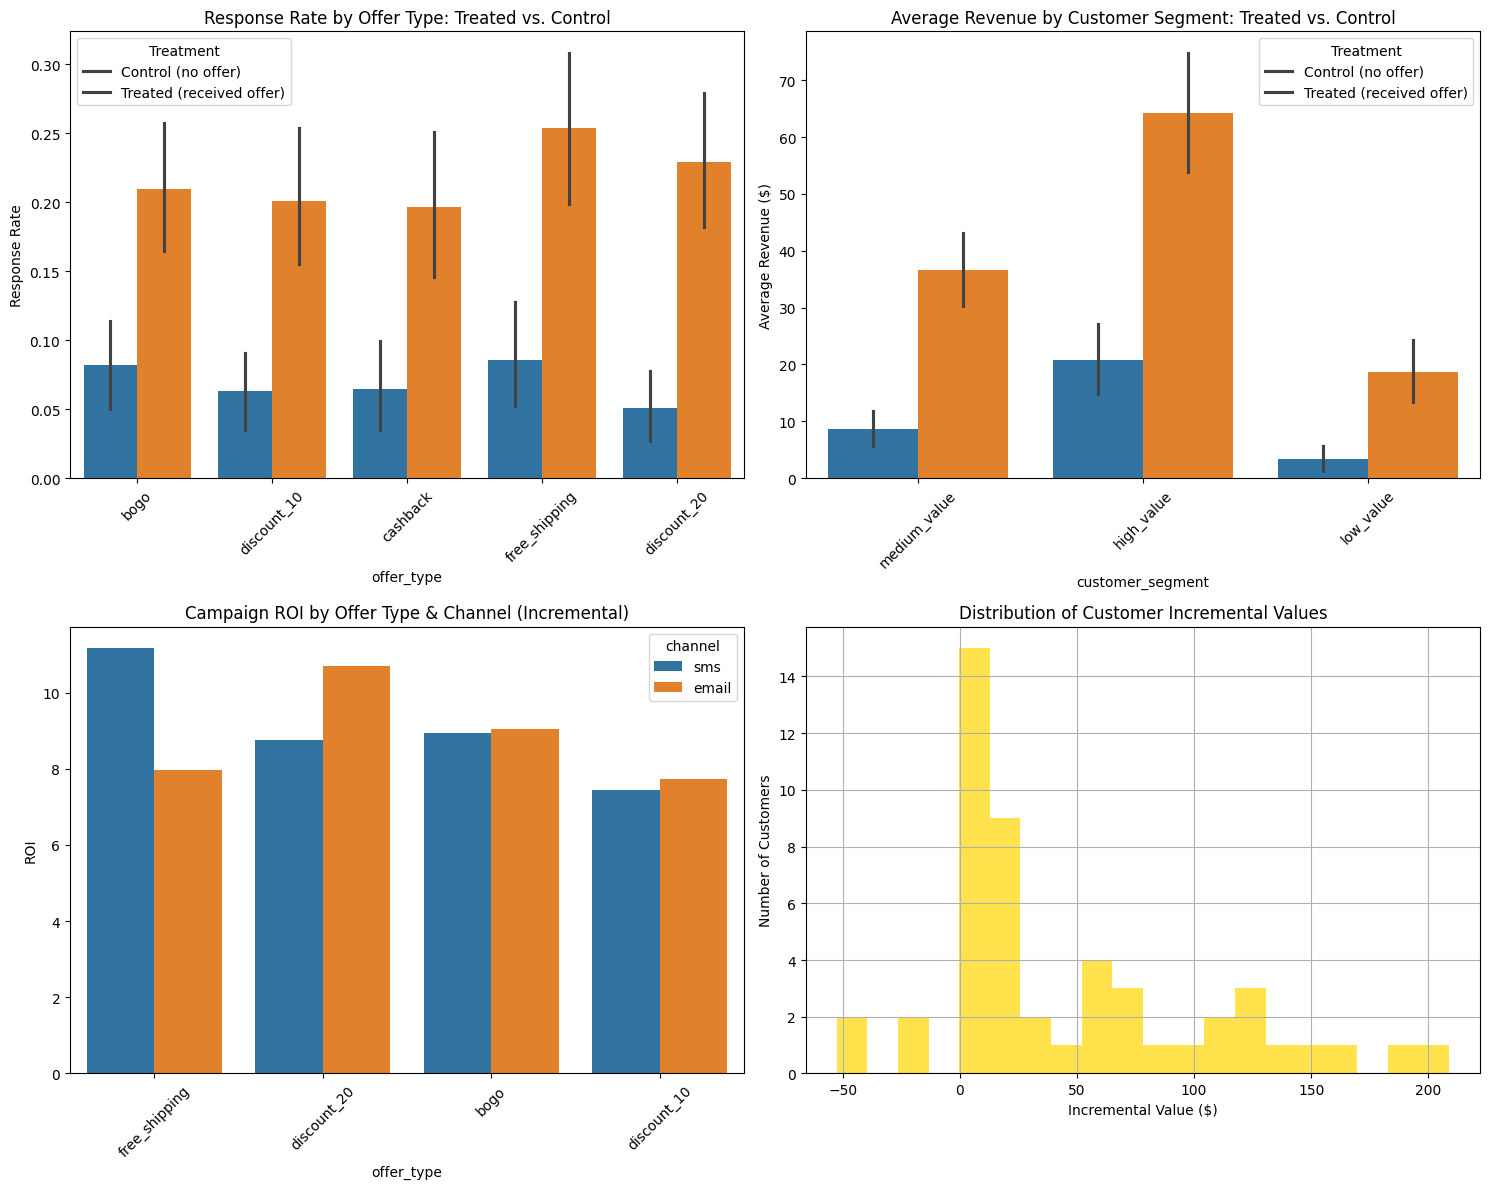

In [15]:
# Visualize offer scoring results
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))

# Response rate by offer type, treatment vs. control - this is the chart
# that makes the uplift visible: the gap between the two bars for each
# offer type IS the effect of that offer.
sns.barplot(data=enhanced_offer_data, x='offer_type', y='responded', hue='treatment', ax=ax1)
ax1.set_title('Response Rate by Offer Type: Treated vs. Control')
ax1.set_ylabel('Response Rate')
ax1.tick_params(axis='x', rotation=45)
ax1.legend(title='Treatment', labels=['Control (no offer)', 'Treated (received offer)'])

# Revenue by customer segment, treatment vs. control
sns.barplot(data=enhanced_offer_data, x='customer_segment', y='revenue', hue='treatment', ax=ax2)
ax2.set_title('Average Revenue by Customer Segment: Treated vs. Control')
ax2.set_ylabel('Average Revenue ($)')
ax2.tick_params(axis='x', rotation=45)
ax2.legend(title='Treatment', labels=['Control (no offer)', 'Treated (received offer)'])

# Campaign ROI by offer type AND channel - grouped by channel so each offer
# type's two channel-specific bars sit side by side, instead of the same
# offer_type label appearing twice as if it were a duplicate.
sns.barplot(data=optimization_results, x='offer_type', y='roi', hue='channel', ax=ax3)
ax3.set_title('Campaign ROI by Offer Type & Channel (Incremental)')
ax3.set_ylabel('ROI')
ax3.tick_params(axis='x', rotation=45)

# Incremental value distribution
campaign_scores['incremental_value'].hist(bins=20, ax=ax4, alpha=0.7, color='gold')
ax4.set_title('Distribution of Customer Incremental Values')
ax4.set_xlabel('Incremental Value ($)')
ax4.set_ylabel('Number of Customers')

plt.tight_layout()
plt.show()
